# 2 · Train YOLO
Train on `labels/`, compare with the current model on `test_set/`, keep the better one.

In [1]:
# setup
import csv, datetime, json, shutil, subprocess, sys, tempfile
from pathlib import Path
import torch, imageio_ffmpeg
from ultralytics import YOLO
from IPython.display import Image, Markdown

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from app import analyse, ACTIVITY

# folders and settings
LABELS, TEST, MODELS = ROOT / "labels", ROOT / "test_set", ROOT / "models"
DATASET = LABELS / "dataset"
DEVICE = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
MAX_MANUAL = 100
NAMES = "names:\n  0: civet\n  1: tray\n  2: food\n"
# show a list of dicts as a table
def table(rows):
    cols = list(rows[0])
    return Markdown("\n".join(["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)] + ["| " + " | ".join(str(r[c]) for c in cols) + " |" for r in rows]))

## Build the training set
Use SAM labels, replaced by manual fixes where given; leave out rejected frames.

In [2]:
# manual fixes (max 100) and rejected frames
manual = {p.stem: p for p in (LABELS / "manual").glob("*.txt")}
assert len(manual) <= MAX_MANUAL, f"{len(manual)} manual labels: the limit is {MAX_MANUAL}"
reject = {l.strip() for l in (LABELS / "reject.txt").read_text().splitlines() if l.strip()}

# every 5th video goes to validation
images = sorted((LABELS / "images").glob("*.jpg"))
video_of = lambda p: p.stem.rsplit("_", 1)[0]
videos = sorted({video_of(p) for p in images})
val_videos = set(videos[::5])

# copy images and labels into train/ and val/
shutil.rmtree(DATASET, ignore_errors=True)
count = {"train": 0, "val": 0, "manual": 0, "rejected": 0}
for img in images:
    if img.stem in reject: count["rejected"] += 1; continue
    split = "val" if video_of(img) in val_videos else "train"
    label = manual.get(img.stem, LABELS / "labels" / f"{img.stem}.txt")   # manual fix wins over SAM
    count["manual"] += img.stem in manual
    for d in ["images", "labels"]: (DATASET / d / split).mkdir(parents=True, exist_ok=True)
    shutil.copy(img, DATASET / "images" / split / img.name); shutil.copy(label, DATASET / "labels" / split / f"{img.stem}.txt")
    count[split] += 1
(DATASET / "data.yaml").write_text(f"path: {DATASET}\ntrain: images/train\nval: images/val\n" + NAMES)
if TEST.exists(): (TEST / "data.yaml").write_text(f"path: {TEST}\ntrain: images\nval: images\n" + NAMES)
print(count, "| validation videos:", sorted(val_videos))
print(f"manual corrections: {count['manual']} of {count['train'] + count['val']} frames")

{'train': 560, 'val': 136, 'manual': 53, 'rejected': 70} | validation videos: ['25690518090944462', '25690518091918610', '25690519194109670', '25690520153014458', 'A04_20260405000000', 'extra_civet_extra_doorway_A04', 'extra_civet_local_locomotion_25690518090944462', 'extra_civet_local_locomotion_25690518091918610', 'extra_civet_local_negative_25690519193808204', 'extra_civet_local_resting_25690520152850102', 'extra_civet_local_review_locomotion_25690518091948946', 'extra_food_tray_A04_20260405000000', 'extra_food_tray_neg_25690519195143424']
manual corrections: 53 of 696 frames


## Train
Train YOLO11n starting from COCO weights.

New https://pypi.org/project/ultralytics/8.4.197 available 😃 Update with 'pip install -U ultralytics'


Ultralytics 8.4.183 🚀 Python-3.12.14 torch-2.14.1 MPS (Apple M3)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/win/dev/university/dip/project/labels/dataset/data.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/Users/win/dev/university/dip/project/models/yolo11n_coco.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=run, nbs=64, nms=None, opset=None, optimize=False, optimizer

Overriding model.yaml nc=80 with nc=3



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


... (6,691 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 4.8it/s 1.9s

                   all        136        168      0.965      0.969      0.981      0.901


Speed: 0.1ms preprocess, 3.1ms inference, 0.0ms loss, 4.7ms postprocess per image


Results saved to /Users/win/dev/university/dip/project/labels/training/run


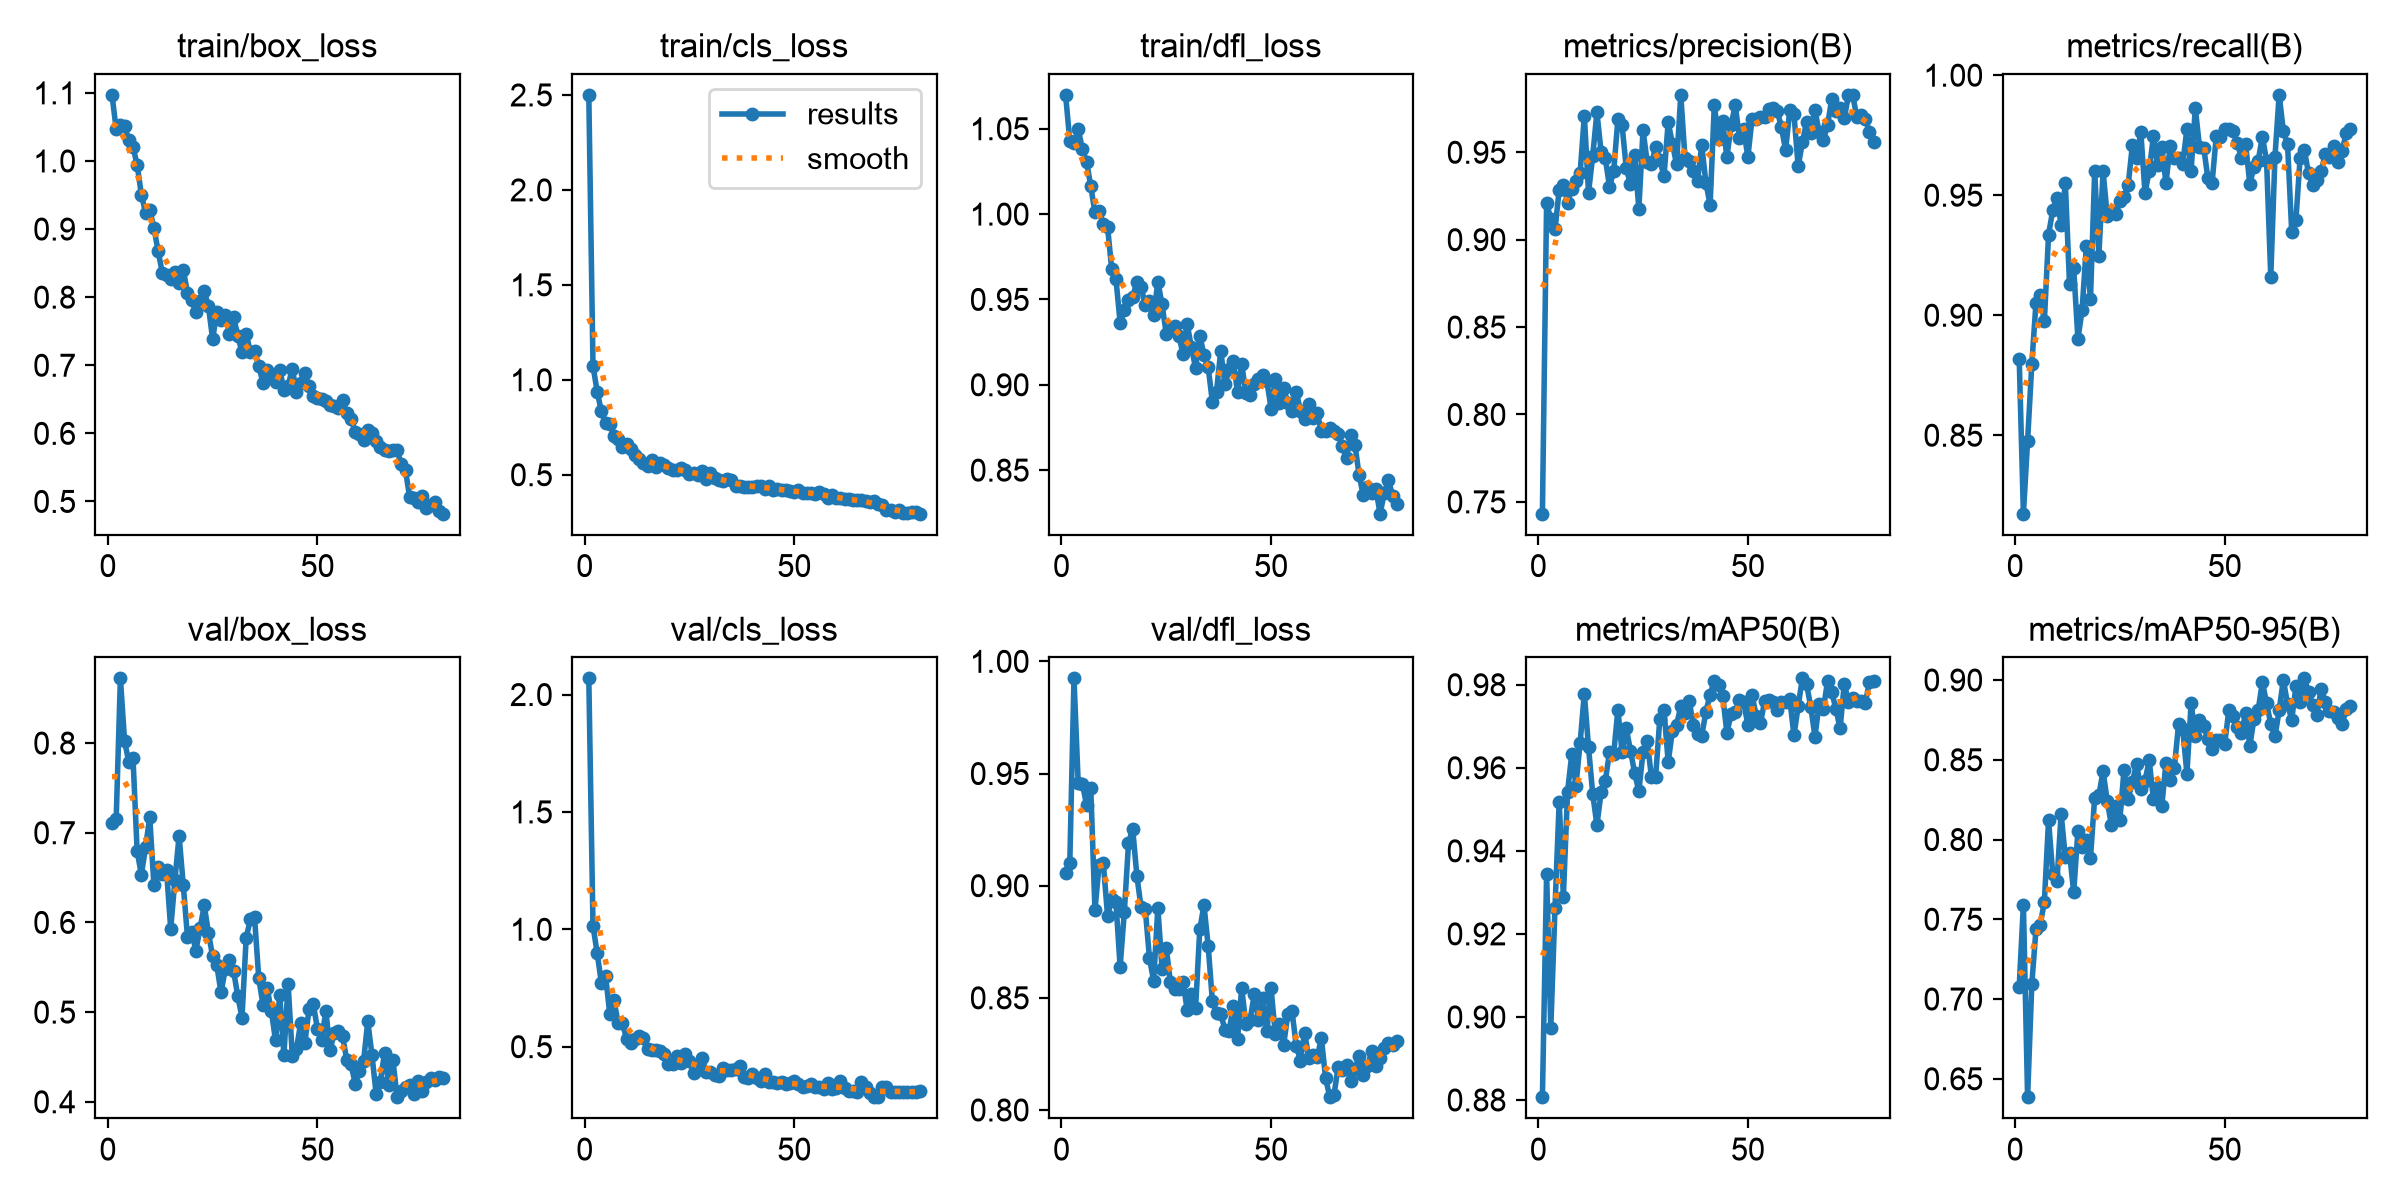

In [3]:
# train and show the training curves
RUN = ROOT / "labels/training"
START = MODELS / "yolo11n_coco.pt" if (MODELS / "yolo11n_coco.pt").exists() else "yolo11n.pt"   # downloaded if missing
YOLO(str(START)).train(data=str(DATASET / "data.yaml"), epochs=80, patience=20, imgsz=640, batch=8,
                                           device=DEVICE, seed=0, project=str(RUN), name="run", exist_ok=True, verbose=False)
new_model = RUN / "run/weights/best.pt"
Image(str(RUN / "run/results.png"))

## Compare
Score both models on the same fixed test set.

In [4]:
# only possible with the original test set and its videos
HAS_TEST = (TEST / "behavior_intervals.csv").exists() and any(ROOT.glob("videos/**/25690519193547292.mp4"))
if HAS_TEST:
    # reference behavior per second for the held-out clips
    ref = {}
    for r in csv.DictReader(open(TEST / "behavior_intervals.csv")):
        for s in range(int(float(r["start_s"])), int(float(r["end_s"]))): ref[(r["recording_id"], s)] = r["behavior"]
    held_out = ["25690518092408866", "25690519193547292", "25690518091012230", "25690518091847591", "25690519194418953", "25690520153258104"]
    clip = lambda name: next(ROOT.glob(f"videos/**/{name}.mp4"))
    # cut the reviewed night clips (not eating)
    tmp = Path(tempfile.mkdtemp()); night = []
    for n in csv.DictReader(open(TEST / "night_negatives.csv")):
        p = tmp / f"{n['video']}_{n['start_s']}.mp4"
        subprocess.run([imageio_ffmpeg.get_ffmpeg_exe(), "-loglevel", "error", "-y", "-ss", n["start_s"], "-t", n["duration_s"],
                        "-i", str(clip(n["video"])), "-an", "-c:v", "libx264", str(p)], check=True)
        night.append(p)

    # box accuracy, behavior accuracy and night false eating for one model
    def score(weights, label):
        m = YOLO(str(weights))
        boxes = m.val(data=str(TEST / "data.yaml"), split="val", device=DEVICE, verbose=False, plots=False).box
        ap = {m.names[int(c)]: round(float(boxes.ap50[k]), 2) for k, c in enumerate(boxes.ap_class_index)}
        pairs = [(ref[(c, r["second"])], "unknown" if r["label"] == "absent" else r["label"])
                 for c in held_out for r in analyse(clip(c), m) if (c, r["second"]) in ref]
        act = lambda x: ACTIVITY.get(x, "unknown")
        return dict(model=label, civet_mAP50=ap.get("civet"), tray_mAP50=ap.get("tray"),
                    behavior=sum(a == p for a, p in pairs), active_inactive=sum(act(a) == act(p) for a, p in pairs), seconds=len(pairs),
                    night_false_eating=sum(r["label"] == "eating" for p in night for r in analyse(p, m)))

    current, new = score(MODELS / "civet_yolo.pt", "current"), score(new_model, "new (SAM labels)")
    table([current, new])
else:
    print("No test set: skipping the comparison.")

[hevc @ 0x127e1eaa0] Could not find ref with POC 0
[hevc @ 0x127e269f0] Could not find ref with POC 0
[hevc @ 0x127e2ded0] Could not find ref with POC 0
[hevc @ 0x127e355c0] Could not find ref with POC 0


[hevc @ 0x12c708be0] Could not find ref with POC 2
[hevc @ 0x12c708be0] Could not find ref with POC 0
[hevc @ 0x12c710c30] Could not find ref with POC 0


Ultralytics 8.4.183 🚀 Python-3.12.14 torch-2.14.1 MPS (Apple M3)


YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 774.2±266.7 MB/s, size: 322.8 KB)


val: Scanning /Users/win/dev/university/dip/project/test_set/labels.cache... 49 images, 20 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 49/49 12.1Mit/s 0.0s

... (13 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 5.5it/s 0.7s

                   all         49         81      0.678      0.664      0.636      0.228


Speed: 0.2ms preprocess, 2.9ms inference, 0.0ms loss, 4.5ms postprocess per image


| model | civet_mAP50 | tray_mAP50 | behavior | active_inactive | seconds | night_false_eating |
|---|---|---|---|---|---|---|
| current | 0.99 | 0.93 | 190 | 192 | 218 | 0 |
| new (SAM labels) | 0.95 | 0.93 | 192 | 195 | 218 | 0 |

## Keep the better model
Replace the app's model only if the new one is at least as good.

In [5]:
# with a test set: replace only if at least as good. Without one: use the new model.
better = not HAS_TEST or (new["behavior"] >= current["behavior"] and new["active_inactive"] >= current["active_inactive"]
                          and new["night_false_eating"] <= current["night_false_eating"])
if better:
    # back up the old model, then replace it
    stamp = datetime.date.today().isoformat()
    (MODELS / "previous").mkdir(exist_ok=True); shutil.copy(MODELS / "civet_yolo.pt", MODELS / "previous" / f"civet_yolo_{stamp}.pt")
    shutil.copy(new_model, MODELS / "civet_yolo.pt")
    print("models/civet_yolo.pt replaced (old one in models/previous/).")
else:
    shutil.copy(new_model, MODELS / "civet_yolo_candidate.pt")
    print("New model is worse on the test set: kept the current model. The new one is saved as models/civet_yolo_candidate.pt.")

New model is at least as good: models/civet_yolo.pt replaced (old one in models/previous/).
